In [1]:
import sys
sys.path.append('/nfs/dataset-ofs-385-143496/yangliu/lite-fea-workspace/wh/demo/thirdparty/copersona/')
from copersona.utils import dmpax, tools


app_name = "home_company_fix56790993302"
spark2conf = {
    "master": "yarn",
    "spark.submit.deployMode": "client",
    "driver-memory": "4g",
    "spark.dynamicAllocation.enabled": "true",
    "spark.dynamicAllocation.minExecutors": "40",
    "spark.dynamicAllocation.maxExecutors": "60",
    "spark.executor.cores": "4",
    "spark.executor.memory": "6g",
    "spark.default.parallelism": "1000",
    "spark.sql.shuffle.partitions": "1000",
    "spark.yarn.queue": "root.profile_prod",
    "spark.sql.autoBroadcastJoinThreshold": "-1",
    "spark.sql.broadcastTimeout": "3000",
    "spark.driver.extraJavaOptions": "-Dcom.github.fommil.netlib.BLAS=com.github.fommil.netlib.F2jBLAS",
    "spark.executor.extraJavaOptions": "-Dcom.github.fommil.netlib.BLAS=com.github.fommil.netlib.F2jBLAS",
    "spark.yarn.dist.archives": "hdfs://difed/user/dm/ENV/dlflow/1.0.1/py3.7.5_for_tfcluster.tgz",
    "spark.executorEnv.PYSPARK_PYTHON": "./py3.7.5_for_tfcluster.tgz/py3.7.5_for_tfcluster/bin/python3",
    "spark.jars": (
        "hdfs://difed/user/dm/ENV/jars/spark_jars/xgboost4j-0.90.jar,"
        "hdfs://difed/user/dm/ENV/jars/spark_jars/xgboost4j-spark-0.90.jar,"
        "hdfs://difed/user/dm/ENV/jars/spark_jars/spark-tensorflow-connector_2.11-1.14.0.jar,"
        "hdfs://difed/user/dm/ENV/jars/spark_jars/tensorflow-hadoop-1.14.0.jar,"
        "hdfs://difed/user/dm/ENV/jars/spark_jars/spark-tfrecord_2.11-0.2.3.jar"
    ),
    "spark.extraListeners": "sparkmonitor.listener.JupyterSparkMonitorListener",
    "spark.driver.extraClassPath": "/opt/miniconda3/lib/python3.7/site-packages/sparkmonitor/listener_2.11.jar"
}


TF211_PY_ENV="hdfs://difed/user/dm/ENV/dlflow/v2/py3.7.15_for_tfcluster.tgz"
TF211_PY_BIN="./py3.7.15_for_tfcluster.tgz/py3.7.15_for_tfcluster/bin/python3"

TF283_PY_ENV="hdfs://difed/user/dm/ENV/zhouyc/tf2.8.3.tgz"
TF283_PY_BIN="./tf2.8.3.tgz/bin/python3"

spark3conf = {
    "master": "yarn",
    "spark.submit.deployMode": "client",
    "driver-memory": "4g",
    "spark.dynamicAllocation.enabled": "true",
    "spark.dynamicAllocation.minExecutors": "10",
    "spark.dynamicAllocation.maxExecutors": "100",
    "spark.executor.cores": "4",
    "spark.executor.memory": "6g",
    "spark.executor.memoryOverhead":"10g",
    "spark.sql.hive.manageFilesourcePartitions":"false",
    "spark.default.parallelism": "200",
    "spark.sql.shuffle.partitions": "200",
    "spark.yarn.queue": "root.profile_prod",
    "spark.sql.autoBroadcastJoinThreshold": "-1",
    "spark.sql.broadcastTimeout": "3000",
    "spark.driver.extraJavaOptions": "-Dcom.github.fommil.netlib.BLAS=com.github.fommil.netlib.F2jBLAS",
    "spark.executor.extraJavaOptions": "-Dcom.github.fommil.netlib.BLAS=com.github.fommil.netlib.F2jBLAS",
    "spark.yarn.dist.archives": "",
    "spark.executorEnv.PYSPARK_PYTHON": "",
    "spark.extraListeners": "sparkmonitor.listener.JupyterSparkMonitorListener",
    "spark.driver.extraClassPath": "/opt/miniconda3/lib/python3.7/site-packages/sparkmonitor/listener_2.12.jar",
    
    
    "spark.jars": (
        "hdfs://difed/user/dm/ENV/jars/spark_tfrecord/compile/spark-tfrecord-0.5.1_scala2.12-spark3.2.0-tfhp1.15.0.jar"
    ),   
}

spark3conf['spark.executorEnv.PYSPARK_PYTHON'] = TF211_PY_BIN
spark3conf['spark.yarn.dist.archives'] = TF211_PY_ENV

spark_app = dmpax.SparkBaseApp()
spark_app.initialize(app_name, spark3conf)
spark = spark_app.spark
hdfs = spark_app.hdfs

print("[Info] Spark Version : {}".format(spark.version))

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
Application Id: application_1782979140233_12640775, Tracking URL: http://bigdata-nmg-hdprm00.nmg01:8088/proxy/application_1782979140233_12640775/
INFO:SparkMonitorKernel:Client Connected ('127.0.0.1', 56966)
INFO:SparkMonitorKernel:Client Connected ('127.0.0.1', 56966)


[Info] Spark Version : 3.2.0-101


In [2]:
import warnings
warnings.filterwarnings("ignore")

import pyspark
import os
import json
import math
import sys
import random
import importlib
import seaborn as sns
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt


import pyspark.sql.types as T
from pyspark.files import SparkFiles
from pyspark.sql   import functions as func
from pyspark.sql   import DataFrame
from pyspark.sql.window import Window
from tqdm import tqdm
from functools import reduce



from ortools.linear_solver import pywraplp
from sklearn.metrics import roc_auc_score


sys.path.append('/nfs/dataset-ofs-385-143496/yangliu/lite-fea-workspace/wh/demo/thirdparty/backflow/')

from backflow import exp_setting
from backflow.programming import pgt
from backflow.calib import metrics as calib_metric
from backflow.calib import stats   as calib_stats
from backflow.visualization import vis
from backflow.programming import simulation as pgtsimu
from backflow.utils import tools as bkfl_tools
import datetime,json
import pandas as pd

from pyspark.sql.functions import col,desc, udf
from pyspark.sql.types import StructType
from pyspark.sql.types import StructField
from pyspark.sql.types import StringType
from pyspark.sql import DataFrame
from pyspark.sql import functions as func


importlib.reload(exp_setting)
importlib.reload(pgt)
importlib.reload(calib_metric)
importlib.reload(calib_stats)
importlib.reload(vis)
importlib.reload(pgtsimu)
importlib.reload(bkfl_tools)


pd.set_option('display.max_columns', None)

load metric func from causalml...
load metric func from causalml...


In [3]:
if True:
    import warnings
    warnings.filterwarnings("ignore")

    import pyspark
    import os
    import json
    import math
    import sys
    import random
    import importlib
    import seaborn as sns
    import numpy as np
    import pandas as pd
    import itertools
    import matplotlib.pyplot as plt
    import matplotlib.pyplot as plt


    import pyspark.sql.types as T
    from pyspark.files import SparkFiles
    from pyspark.sql   import functions as func
    from pyspark.sql   import DataFrame
    from pyspark.sql.window import Window
    from tqdm import tqdm
    from functools import reduce

    from sklearn.metrics import roc_auc_score

    import datetime,json
    import pandas as pd

    from pyspark.sql.functions import col,desc, udf
    from pyspark.sql.types import StructType
    from pyspark.sql.types import StructField
    from pyspark.sql.types import StringType
    from pyspark.sql import DataFrame
    from pyspark.sql import functions as func

    

    pd.set_option('display.max_columns', None)

In [ ]:
# 把真实label表和模型推理的数据拼接起来
# uplift_1：留存6张3元相对control组的预测 uplift；uplift_2: {8元留存5张3} 相对 {留存6张3元}的uplift. as left853_minus_left63
# left853: 模型预测的{8元留存5张3}相对control组 的总 uplift


# baseline:473个特征
label_dt是从label_di/train_di里取的，不用错开日期，直接对齐即可

In [4]:
BASE_FMT_v1 = spark.sql("""
with base as (
    select *,
        finish_cnt_7d as label,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d
    from dm.ut_alg_flowback_msg_outcall_label_di
    where dt between '2026-06-23' and '2026-07-06'
    and new_exp = '迭代流量'
    and ((group_name_eve in ('留存6张5元', '留存6张3元', '8元留存5张3', '10元留存5张3')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),

mapping_data as (
    select
        pid,
        label_dt as dt,
        treatment as model_treatment,

        uplift_1 as left63,
        uplift_2 as left853,
        uplift_3 as left65,
        uplift_4 as left1053,
        cost_1,
        cost_2,
        cost_3,
        cost_4

    from growstrategy.ut_msg_outcall_feature_select_baseline_month_5_6_model_inference_di

    where label_dt between '2026-06-23' and '2026-07-06'
),

prediction_agg as (
    select 
        bs.*,
        case when bs.group_name_eve = '10元留存5张3' then 4
             when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'control_group' then 0
             else null
        end as real_treatment,
        
        mapping_data.model_treatment,

        nvl(mapping_data.left63, 999) as left63,
        nvl(mapping_data.left853, 999) as left853,
        nvl(mapping_data.left65, 999) as left65,
        nvl(mapping_data.left1053, 999) as left1053,
        
        
        case
            when nvl(mapping_data.left853, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left853 - mapping_data.left63
        end as left853_minus_left63,

        case
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left63
        end as left65_minus_left63,
        case
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left853
        end as left65_minus_left853,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left63
        end as left1053_minus_left63,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left853
        end as left1053_minus_left853,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left65, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left65
        end as left1053_minus_left65,
    
        mapping_data.cost_1,
        mapping_data.cost_2,
        mapping_data.cost_3,
        mapping_data.cost_4
        
    from base bs
    join mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)
select *
from prediction_agg
""").toPandas()

BASE_FMT_v1.head(25)

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost_7d,real_treatment,model_treatment,left63,left853,left65,left1053,left853_minus_left63,left65_minus_left63,left65_minus_left853,left1053_minus_left63,left1053_minus_left853,left1053_minus_left65,cost_1,cost_2,cost_3,cost_4
0,迭代流量,DS空白,DS空白,control_group,1000074772481,v1_871b0d48c8d63a3f44dcab0f61c78055,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-06-27,0.0,0.000,0,0.0,0.004256,0.004070,0.007108,0.013314,-1.859134e-04,0.002852,0.003038,0.009058,0.009244,0.006206,0.030093,0.034631,0.068488,0.080440
1,迭代流量,DS空白,DS空白,control_group,100017818,v1_17592452007267,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,2026-06-27,0.0,0.000,0,0.0,0.046333,0.056802,0.078859,0.084063,1.046860e-02,0.032526,0.022057,0.037730,0.027261,0.005204,0.235998,0.449614,0.952809,0.768015
2,迭代流量,探索,探索,8元留存5张3,100019691,v1_17593047104776,2.0,1.0,0.021,0.0,1.0,0.12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-06-24,0.0,0.141,2,2.0,0.020483,0.026707,0.036990,0.040002,6.223885e-03,0.016507,0.010283,0.019519,0.013295,0.003012,0.120592,0.184246,0.339285,0.314820
3,迭代流量,DS空白,DS空白,control_group,1000347541507,v1_17592728950962,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-06-26,0.0,0.000,0,0.0,0.005742,0.006581,0.009389,0.016295,8.391459e-04,0.003647,0.002808,0.010553,0.009714,0.006906,0.036849,0.045147,0.072611,0.091268
4,迭代流量,DS空白,DS空白,control_group,1000347541507,v1_17592728950962,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.0,2026-06-30,0.0,0.000,0,0.0,0.004194,0.004077,0.007530,0.012893,-1.168116e-04,0.003336,0.003452,0.008699,0.008816,0.005363,0.026271,0.026901,0.062215,0.069593
5,迭代流量,DS空白,DS空白,control_group,100051270,v1_17592993205983,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,29.0,2026-07-04,0.0,0.000,0,0.0,0.000591,0.000590,0.004473,0.008091,-8.693896e-07,0.003882,0.003883,0.007500,0.007500,0.003618,0.012816,0.010617,0.054687,0.045634
6,迭代流量,探索,探索,10元留存5张3,100311305,v1_17592815488577,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-06-25,0.0,0.000,4,4.0,0.035675,0.043864,0.062552,0.068576,8.189272e-03,0.026877,0.018688,0.032902,0.024712,0.006024,0.180052,0.319857,0.645930,0.603710
7,迭代流量,DS空白,DS空白,control_group,100420097,v1_17592689221619,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,28.0,2026-06-27,0.0,0.000,0,0.0,-0.000892,-0.002975,0.000897,0.004915,-2.082312e-03,0.001789,0.003872,0.005808,0.007890,0.004019,0.010235,0.005726,0.058322,0.047840
8,迭代流量,DS空白,DS空白,control_group,100435300354,v1_17592720902128,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.0,2026-06-25,0.0,0.000,0,0.0,0.004956,0.007271,0.008681,0.017340,2.315036e-03,0.003725,0.001410,0.012385,0.010069,0.008659,0.033137,0.034918,0.073552,0.101685
9,迭代流量,探索,探索,8元留存5张3,100637806596,v1_17592753880670,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.0,2026-07-01,0.0,0.000,2,2.0,-0.003459,-0.005722,-0.001174,0.001485,-2.263078e-03,0.002285,0.004548,0.004944,0.007207,0.002659,0.003234,-0.001634,0.055800,0.038668


In [11]:
# 1. 验证发券 & 成本的增效逻辑: 
'''
同张数不同面额，或者是同面额不同张数这种 才满足单调性
此处不做验证

'''

In [10]:
import pandas as pd

# 1. 过滤未匹配到的异常值
cols_to_check = [
    'left63', 'left853', 'left65', 'left1053',
    'left853_minus_left63',
    'left65_minus_left63',
    'left1053_minus_left63',
    'cost_1', 'cost_2', 'cost_3', 'cost_4'
]

valid_mask = ~BASE_FMT_v1[cols_to_check].isin([999]).any(axis=1)
df_valid = BASE_FMT_v1[valid_mask].copy()
total_samples = len(df_valid)

# 2. CVR / uplift 增效逻辑
# 假设业务强度顺序是：
# 留存6张3元 < 8元留存5张3 < 留存6张5元 < 第4组
cond_cvr = (
    (df_valid['left63'] >= 0) &
    (df_valid['left853'] > df_valid['left63']) &
    (df_valid['left65'] > df_valid['left853']) &
    (df_valid['left1053'] > df_valid['left65'])
)

# 3. Cost 成本递增逻辑
cond_cost = (
    (df_valid['cost_1'] >= 0) &
    (df_valid['cost_2'] > df_valid['cost_1']) &
    (df_valid['cost_3'] > df_valid['cost_2']) &
    (df_valid['cost_4'] > df_valid['cost_3'])
)

# 4. 两者同时满足
cond_both = cond_cvr & cond_cost

# 5. 输出报告
print("========== 深入拆解：CVR 与 Cost 满足比例 ==========\n")
print(f"底座总有效样本数 : {total_samples:,} 条\n")

cvr_count = cond_cvr.sum()
print("【1. 只看 CVR / uplift 增效顺序】")
print(f"   - 满足条数: {cvr_count:,}")
print(f"   - 不满足条数: {total_samples - cvr_count:,}")
print(f"   => 满足比例: {cvr_count / total_samples:.2%}\n")

cost_count = cond_cost.sum()
print("【2. 只看 Cost 成本递增顺序】")
print(f"   - 满足条数: {cost_count:,}")
print(f"   - 不满足条数: {total_samples - cost_count:,}")
print(f"   => 满足比例: {cost_count / total_samples:.2%}\n")

both_count = cond_both.sum()
print("【3. CVR 与 Cost 同时满足】")
print(f"   - 满足条数: {both_count:,}")
print(f"   - 不满足条数: {total_samples - both_count:,}")
print(f"   => 满足比例: {both_count / total_samples:.2%}")
print("==================================================")


========== 深入拆解：CVR 与 Cost 满足比例 ==========

底座总有效样本数 : 1,749,546 条

【1. 只看 CVR / uplift 增效顺序】
   - 满足条数: 1,097,941
   - 不满足条数: 651,605
   => 满足比例: 62.76%

【2. 只看 Cost 成本递增顺序】
   - 满足条数: 932,405
   - 不满足条数: 817,141
   => 满足比例: 53.29%

【3. CVR 与 Cost 同时满足】
   - 满足条数: 815,030
   - 不满足条数: 934,516
   => 满足比例: 46.59%


In [ ]:
# auuc：评估干预组vs对照组 & 干预组之间（残差）

left63    0.840971
Random    0.497577
dtype: float64
****************************************
left853    0.847147
Random     0.501844
dtype: float64
****************************************
left65    0.843281
Random    0.494879
dtype: float64
****************************************
left1053    0.823233
Random      0.498230
dtype: float64
****************************************


[left63    0.840971
 Random    0.497577
 dtype: float64,
 left853    0.847147
 Random     0.501844
 dtype: float64,
 left65    0.843281
 Random    0.494879
 dtype: float64,
 left1053    0.823233
 Random      0.498230
 dtype: float64]

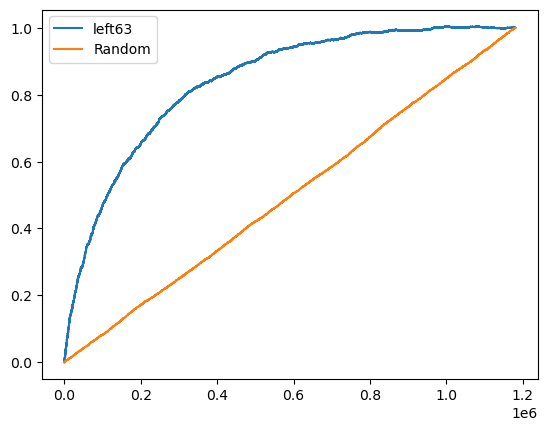

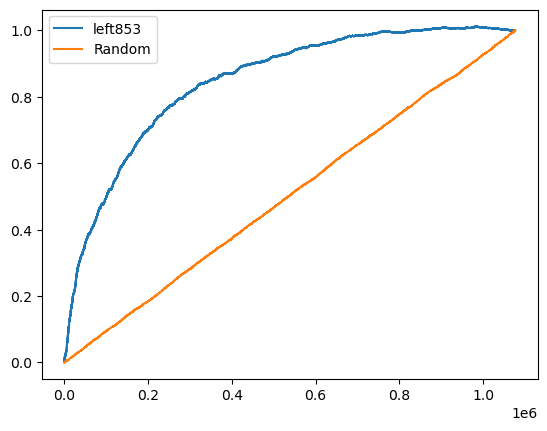

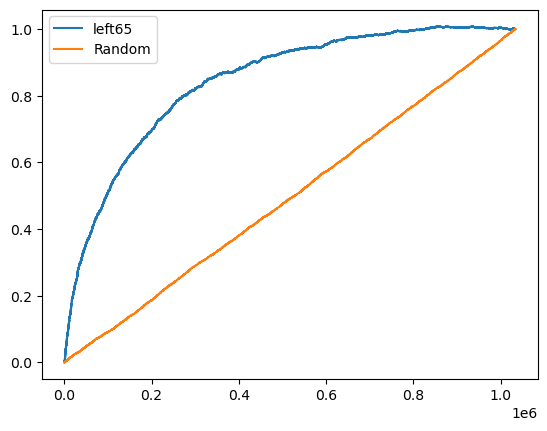

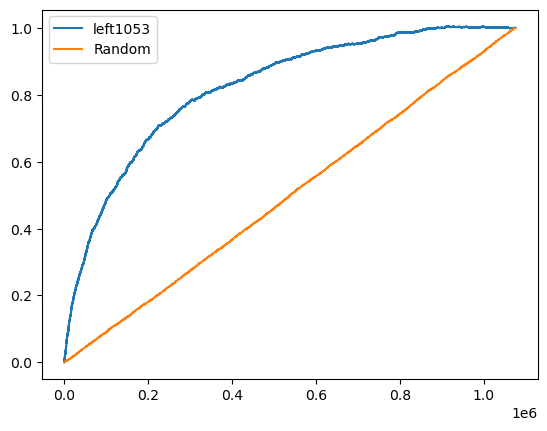

In [12]:
vis.draw_auuc(
    BASE_FMT_v1,
    treatments=[1, 2, 3, 4],
    ite_names=['left63', 'left853', 'left65', 'left1053'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=0,
    show_curve=1
)

left853_minus_left63    0.890155
Random                  0.518085
dtype: float64
****************************************


[left853_minus_left63    0.890155
 Random                  0.518085
 dtype: float64]

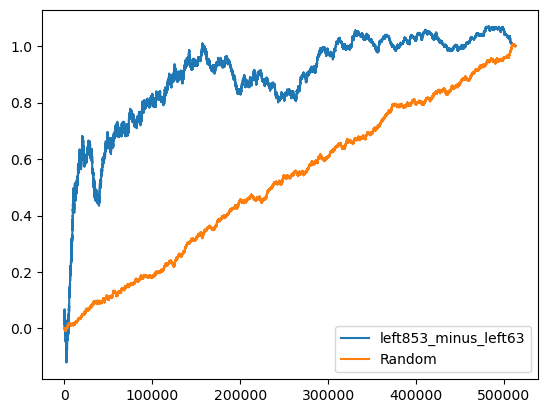

In [13]:
# 从 6张3元 升级到 8元+5张3：
vis.draw_auuc(
    BASE_FMT_v1,
    treatments=[2], #8元+5张3
    ite_names=['left853_minus_left63'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=1,
    show_curve=1
)

left65_minus_left63    0.884317
Random                 0.479775
dtype: float64
****************************************


[left65_minus_left63    0.884317
 Random                 0.479775
 dtype: float64]

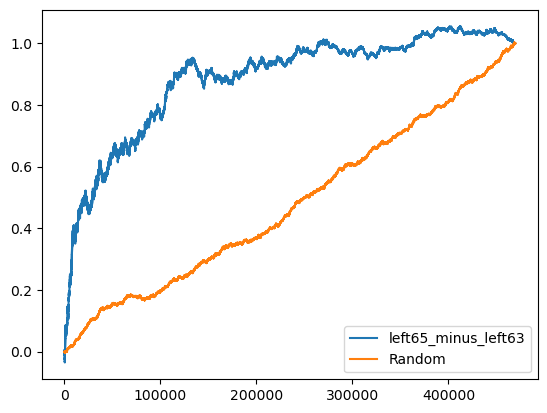

In [14]:
# 从 6张3元 升级到6张5元
vis.draw_auuc(
    BASE_FMT_v1,
    treatments=[3],
    ite_names=['left65_minus_left63'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=1,
    show_curve=1
)

left1053_minus_left63    0.763441
Random                   0.505995
dtype: float64
****************************************


[left1053_minus_left63    0.763441
 Random                   0.505995
 dtype: float64]

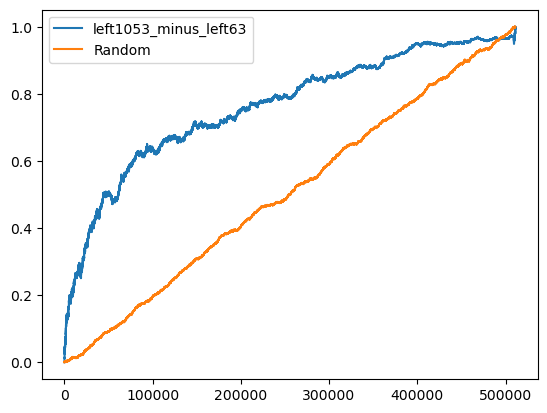

In [15]:
vis.draw_auuc(
    BASE_FMT_v1,
    treatments=[4],
    ite_names=['left1053_minus_left63'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=1,
    show_curve=1
)

In [ ]:
# cost auc

In [ ]:
#pv维度的auc
def caculate_auc(y_labels,y_scores):
    label_unique=list(set(y_labels))
    label_unique.sort(reverse=True)

    # print("label 种类：")
    # print(label_unique)
    f = list(zip(y_scores, y_labels))
    rank = [values2 for values1, values2 in sorted(f, key=lambda x:x[0])] # 根据核销概率进行排序
    cnt=0
    for label in label_unique:
        if label==0:
            continue
        label_dict={}
        for item in label_unique:
            label_dict[item]=0
        #rank根据打分从小到大排序，for循环从小到大遍历到当前标签时，计算前面打分小的label中真正比当前label小的个数
        for i in range(len(rank)):
            if rank[i]==label:
                for item in label_unique:
                    if item<label:
                        cnt+=label_dict[item]

            label_dict[rank[i]]+=1
    label_dict={}
    for item in y_labels:
        if item not in label_dict:
            label_dict[item]=0
        label_dict[item]+=1
    total_len=0
    label_num=len(y_labels)
    for i in range(len(label_unique)-1):
        total_len=total_len+label_dict[label_unique[i]]*(label_num-label_dict[label_unique[i]])
        # print(total_len)
        label_num=label_num-label_dict[label_unique[i]]

    return cnt/total_len

In [ ]:
left6_df =  BASE_FMT_v2 [BASE_FMT_v1['group_name_eve']=='留存6张3元']   # 1
caculate_auc(left6_df['cost'], left6_df['coupon_prob'])

In [ ]:
# 删除sirius画像特征

In [16]:
BASE_FMT_v2 = spark.sql("""
with base as (
    select *,
        finish_cnt_7d as label,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d
    from dm.ut_alg_flowback_msg_outcall_label_di
    where dt between '2026-06-23' and '2026-07-06'
    and new_exp = '迭代流量'
    and ((group_name_eve in ('留存6张5元', '留存6张3元', '8元留存5张3', '10元留存5张3')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),

mapping_data as (
    select
        pid,
        label_dt as dt,
        treatment as model_treatment,

        uplift_1 as left63,
        uplift_2 as left853,
        uplift_3 as left65,
        uplift_4 as left1053,
        cost_1,
        cost_2,
        cost_3,
        cost_4

    from growstrategy.ut_msg_outcall_feature_select_nosirius_month_5_6_model_inference_di

    where label_dt between '2026-06-23' and '2026-07-06'
),

prediction_agg as (
    select 
        bs.*,
        case when bs.group_name_eve = '10元留存5张3' then 4
             when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'control_group' then 0
             else null
        end as real_treatment,
        
        mapping_data.model_treatment,

        nvl(mapping_data.left63, 999) as left63,
        nvl(mapping_data.left853, 999) as left853,
        nvl(mapping_data.left65, 999) as left65,
        nvl(mapping_data.left1053, 999) as left1053,
        
        
        case
            when nvl(mapping_data.left853, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left853 - mapping_data.left63
        end as left853_minus_left63,

        case
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left63
        end as left65_minus_left63,
        case
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left853
        end as left65_minus_left853,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left63
        end as left1053_minus_left63,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left853
        end as left1053_minus_left853,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left65, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left65
        end as left1053_minus_left65,
    
        mapping_data.cost_1,
        mapping_data.cost_2,
        mapping_data.cost_3,
        mapping_data.cost_4
        
    from base bs
    join mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)
select *
from prediction_agg
""").toPandas()

BASE_FMT_v2.head(25)

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost_7d,real_treatment,model_treatment,left63,left853,left65,left1053,left853_minus_left63,left65_minus_left63,left65_minus_left853,left1053_minus_left63,left1053_minus_left853,left1053_minus_left65,cost_1,cost_2,cost_3,cost_4
0,迭代流量,DS空白,DS空白,control_group,1000074772481,v1_871b0d48c8d63a3f44dcab0f61c78055,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-06-27,0.0,0.000,0,0.0,0.004959,0.005720,0.009797,0.013910,0.000760,0.004838,0.004077,0.008951,0.008190,0.004113,0.032889,0.037649,0.071946,0.077187
1,迭代流量,DS空白,DS空白,control_group,100017818,v1_17592452007267,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,2026-06-27,0.0,0.000,0,0.0,0.057869,0.071217,0.099410,0.094440,0.013349,0.041542,0.028193,0.036571,0.023222,-0.004970,0.280573,0.556143,0.942976,0.732076
2,迭代流量,探索,探索,8元留存5张3,100019691,v1_17593047104776,2.0,1.0,0.021,0.0,1.0,0.12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-06-24,0.0,0.141,2,2.0,0.018975,0.024769,0.031344,0.033929,0.005794,0.012369,0.006575,0.014955,0.009160,0.002586,0.119059,0.180989,0.276489,0.272108
3,迭代流量,DS空白,DS空白,control_group,1000347541507,v1_17592728950962,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-06-26,0.0,0.000,0,0.0,0.002386,0.001913,0.007737,0.010108,-0.000473,0.005351,0.005824,0.007722,0.008195,0.002371,0.030891,0.028450,0.078280,0.055135
4,迭代流量,DS空白,DS空白,control_group,1000347541507,v1_17592728950962,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.0,2026-06-30,0.0,0.000,0,0.0,0.002507,0.002477,0.008057,0.010591,-0.000030,0.005550,0.005580,0.008084,0.008114,0.002534,0.027588,0.024259,0.066905,0.046410
5,迭代流量,DS空白,DS空白,control_group,100051270,v1_17592993205983,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,29.0,2026-07-04,0.0,0.000,0,0.0,0.001640,0.000670,0.005836,0.009610,-0.000971,0.004195,0.005166,0.007969,0.008940,0.003774,0.014967,0.012386,0.047526,0.031387
6,迭代流量,探索,探索,10元留存5张3,100311305,v1_17592815488577,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-06-25,0.0,0.000,4,4.0,0.067285,0.080552,0.118536,0.110111,0.013267,0.051251,0.037983,0.042826,0.029559,-0.008425,0.339328,0.664102,1.161255,0.930416
7,迭代流量,DS空白,DS空白,control_group,100420097,v1_17592689221619,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,28.0,2026-06-27,0.0,0.000,0,0.0,0.001358,-0.000013,0.006291,0.009709,-0.001371,0.004933,0.006304,0.008351,0.009722,0.003418,0.015862,0.013713,0.060160,0.035813
8,迭代流量,DS空白,DS空白,control_group,100435300354,v1_17592720902128,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.0,2026-06-25,0.0,0.000,0,0.0,0.005664,0.006891,0.011661,0.016107,0.001228,0.005998,0.004770,0.010443,0.009216,0.004446,0.035223,0.039977,0.074721,0.091016
9,迭代流量,探索,探索,8元留存5张3,100637806596,v1_17592753880670,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.0,2026-07-01,0.0,0.000,2,2.0,-0.001846,-0.005076,0.001966,0.006490,-0.003230,0.003812,0.007042,0.008336,0.011566,0.004524,0.006100,0.000170,0.050041,0.021992


left63    0.843582
Random    0.497577
dtype: float64
****************************************
left853    0.837167
Random     0.501844
dtype: float64
****************************************
left65    0.834867
Random    0.494879
dtype: float64
****************************************
left1053    0.825597
Random      0.498230
dtype: float64
****************************************


[left63    0.843582
 Random    0.497577
 dtype: float64,
 left853    0.837167
 Random     0.501844
 dtype: float64,
 left65    0.834867
 Random    0.494879
 dtype: float64,
 left1053    0.825597
 Random      0.498230
 dtype: float64]

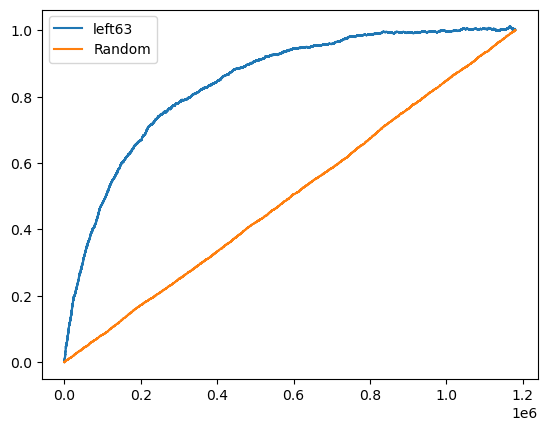

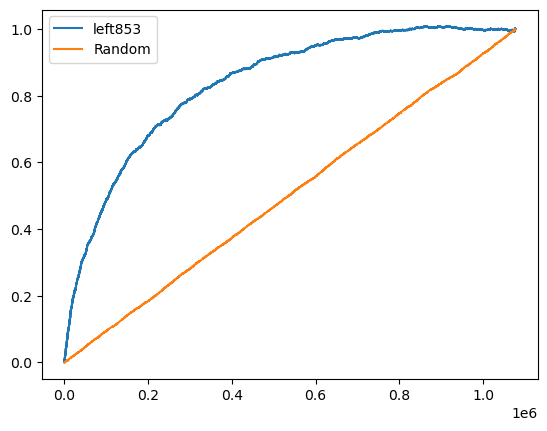

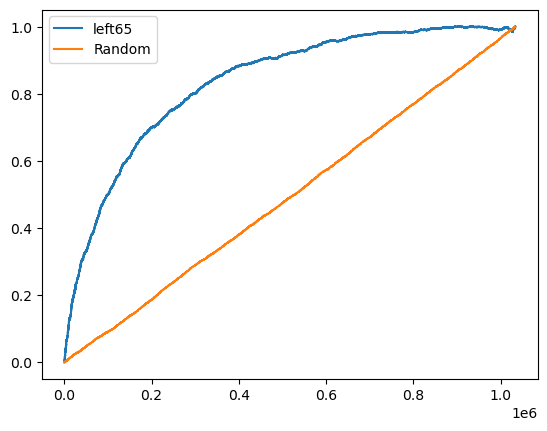

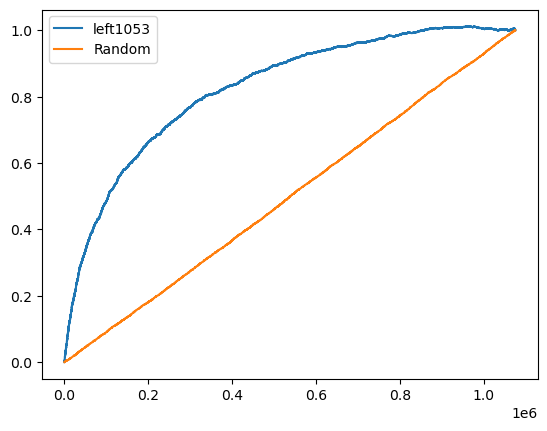

In [21]:
vis.draw_auuc(
    BASE_FMT_v2,
    treatments=[1, 2, 3, 4],
    ite_names=['left63', 'left853', 'left65', 'left1053'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=0,
    show_curve=1
)

left853_minus_left63    0.773788
Random                  0.518085
dtype: float64
****************************************


[left853_minus_left63    0.773788
 Random                  0.518085
 dtype: float64]

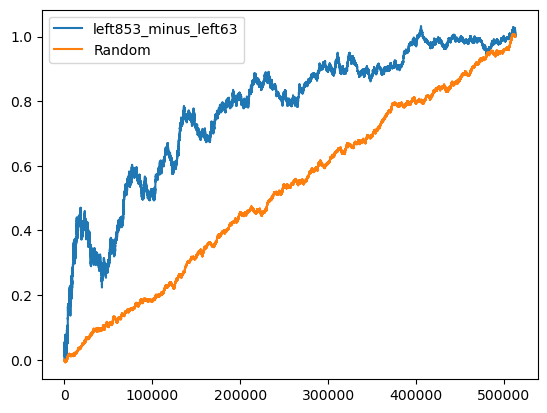

In [22]:
# 从 6张3元 升级到 8元+5张3：
vis.draw_auuc(
    BASE_FMT_v2,
    treatments=[2], #8元+5张3
    ite_names=['left853_minus_left63'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=1,
    show_curve=1
)

left65_minus_left63    0.791685
Random                 0.479775
dtype: float64
****************************************


[left65_minus_left63    0.791685
 Random                 0.479775
 dtype: float64]

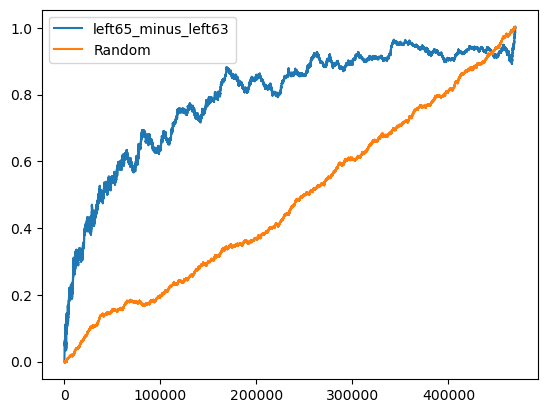

In [23]:
# 从 6张3元 升级到6张5元
vis.draw_auuc(
    BASE_FMT_v2,
    treatments=[3],
    ite_names=['left65_minus_left63'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=1,
    show_curve=1
)

left1053_minus_left63    0.771182
Random                   0.505995
dtype: float64
****************************************


[left1053_minus_left63    0.771182
 Random                   0.505995
 dtype: float64]

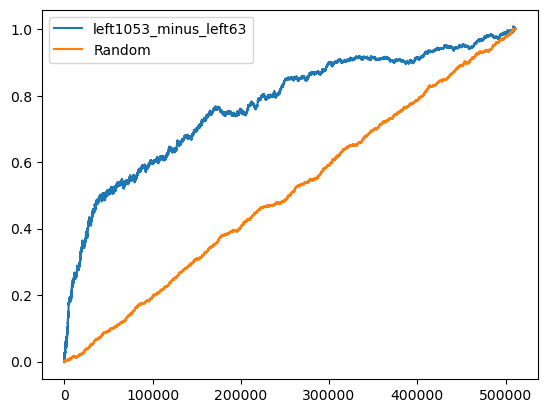

In [24]:
vis.draw_auuc(
    BASE_FMT_v2,
    treatments=[4],
    ite_names=['left1053_minus_left63'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=1,
    show_curve=1
)

In [26]:
BASE_FMT_v3 = spark.sql("""
with base as (
    select *,
        finish_cnt_7d as label,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d
    from dm.ut_alg_flowback_msg_outcall_label_di
    where dt between '2026-06-23' and '2026-07-06'
    and new_exp = '迭代流量'
    and ((group_name_eve in ('留存6张5元', '留存6张3元', '8元留存5张3', '10元留存5张3')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),

mapping_data as (
    select
        pid,
        label_dt as dt,
        treatment as model_treatment,

        uplift_1 as left63,
        uplift_2 as left853,
        uplift_3 as left65,
        uplift_4 as left1053,
        cost_1,
        cost_2,
        cost_3,
        cost_4

    from growstrategy.ut_msg_outcall_feature_select_replace_order_month_5_6_model_inference_di

    where label_dt between '2026-06-23' and '2026-07-06'
),

prediction_agg as (
    select 
        bs.*,
        case when bs.group_name_eve = '10元留存5张3' then 4
             when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'control_group' then 0
             else null
        end as real_treatment,
        
        mapping_data.model_treatment,

        nvl(mapping_data.left63, 999) as left63,
        nvl(mapping_data.left853, 999) as left853,
        nvl(mapping_data.left65, 999) as left65,
        nvl(mapping_data.left1053, 999) as left1053,
        
        
        case
            when nvl(mapping_data.left853, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left853 - mapping_data.left63
        end as left853_minus_left63,

        case
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left63
        end as left65_minus_left63,
        case
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left853
        end as left65_minus_left853,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left63
        end as left1053_minus_left63,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left853
        end as left1053_minus_left853,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left65, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left65
        end as left1053_minus_left65,
    
        mapping_data.cost_1,
        mapping_data.cost_2,
        mapping_data.cost_3,
        mapping_data.cost_4
        
    from base bs
    join mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)
select *
from prediction_agg
""").toPandas()

BASE_FMT_v3.head(25)

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost_7d,real_treatment,model_treatment,left63,left853,left65,left1053,left853_minus_left63,left65_minus_left63,left65_minus_left853,left1053_minus_left63,left1053_minus_left853,left1053_minus_left65,cost_1,cost_2,cost_3,cost_4
0,迭代流量,DS空白,DS空白,control_group,1000074772481,v1_871b0d48c8d63a3f44dcab0f61c78055,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-06-27,0.0,0.000,0,0.0,0.003878,0.002821,0.006685,0.011340,-0.001057,0.002808,0.003865,0.007462,0.008519,0.004654,0.028861,0.023090,0.067957,0.069437
1,迭代流量,DS空白,DS空白,control_group,100017818,v1_17592452007267,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,2026-06-27,0.0,0.000,0,0.0,0.032570,0.039683,0.050096,0.067362,0.007113,0.017526,0.010413,0.034792,0.027679,0.017266,0.167441,0.280857,0.461438,0.502013
2,迭代流量,探索,探索,8元留存5张3,100019691,v1_17593047104776,2.0,1.0,0.021,0.0,1.0,0.12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-06-24,0.0,0.141,2,2.0,0.013947,0.017647,0.017601,0.024610,0.003699,0.003653,-0.000046,0.010662,0.006963,0.007009,0.083289,0.119673,0.157206,0.190809
3,迭代流量,DS空白,DS空白,control_group,1000347541507,v1_17592728950962,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-06-26,0.0,0.000,0,0.0,0.003779,0.002012,0.006116,0.009928,-0.001767,0.002337,0.004104,0.006149,0.007916,0.003812,0.037385,0.040474,0.099792,0.076368
4,迭代流量,DS空白,DS空白,control_group,1000347541507,v1_17592728950962,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.0,2026-06-30,0.0,0.000,0,0.0,0.003631,0.002016,0.006407,0.010022,-0.001615,0.002776,0.004390,0.006391,0.008006,0.003616,0.041153,0.046372,0.108996,0.091058
5,迭代流量,DS空白,DS空白,control_group,100051270,v1_17592993205983,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,29.0,2026-07-04,0.0,0.000,0,0.0,0.001791,-0.000589,0.002929,0.009285,-0.002380,0.001138,0.003518,0.007494,0.009874,0.006356,0.016919,0.008538,0.033090,0.026691
6,迭代流量,探索,探索,10元留存5张3,100311305,v1_17592815488577,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-06-25,0.0,0.000,4,4.0,0.051005,0.061005,0.082694,0.095926,0.010000,0.031689,0.021689,0.044922,0.034921,0.013233,0.237263,0.414494,0.698170,0.726943
7,迭代流量,DS空白,DS空白,control_group,100420097,v1_17592689221619,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,28.0,2026-06-27,0.0,0.000,0,0.0,0.000146,-0.004521,0.000569,0.006819,-0.004667,0.000423,0.005090,0.006674,0.011340,0.006251,0.011249,-0.001177,0.032992,0.021779
8,迭代流量,DS空白,DS空白,control_group,100435300354,v1_17592720902128,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.0,2026-06-25,0.0,0.000,0,0.0,0.006457,0.006318,0.010902,0.015549,-0.000139,0.004444,0.004583,0.009092,0.009231,0.004648,0.037133,0.040396,0.094018,0.106600
9,迭代流量,探索,探索,8元留存5张3,100637806596,v1_17592753880670,0.0,0.0,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.0,2026-07-01,0.0,0.000,2,2.0,0.000089,-0.006676,-0.000943,0.006527,-0.006765,-0.001032,0.005733,0.006438,0.013203,0.007470,0.005315,-0.009721,0.026093,0.013683


left63    0.835287
Random    0.497577
dtype: float64
****************************************
left853    0.836616
Random     0.501844
dtype: float64
****************************************
left65    0.832025
Random    0.494879
dtype: float64
****************************************
left1053    0.827608
Random      0.498230
dtype: float64
****************************************


[left63    0.835287
 Random    0.497577
 dtype: float64,
 left853    0.836616
 Random     0.501844
 dtype: float64,
 left65    0.832025
 Random    0.494879
 dtype: float64,
 left1053    0.827608
 Random      0.498230
 dtype: float64]

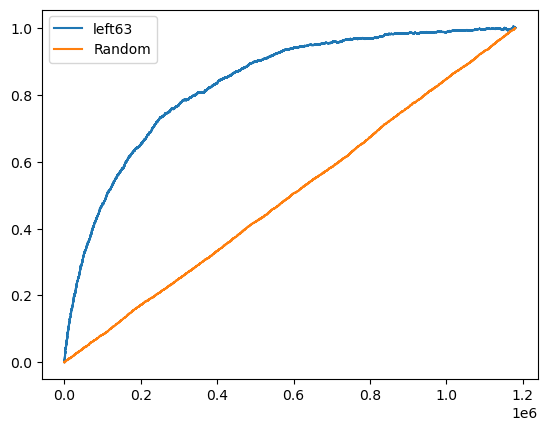

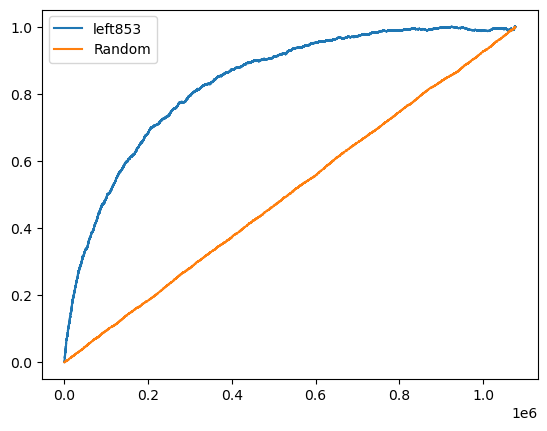

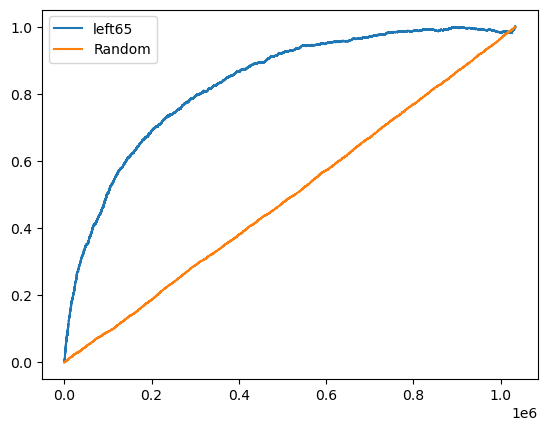

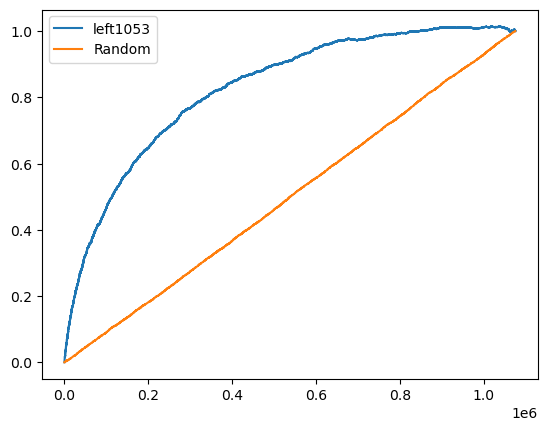

In [27]:
vis.draw_auuc(
    BASE_FMT_v3,
    treatments=[1, 2, 3, 4],
    ite_names=['left63', 'left853', 'left65', 'left1053'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=0,
    show_curve=1
)

left853_minus_left63    0.822610
Random                  0.518085
dtype: float64
****************************************


[left853_minus_left63    0.822610
 Random                  0.518085
 dtype: float64]

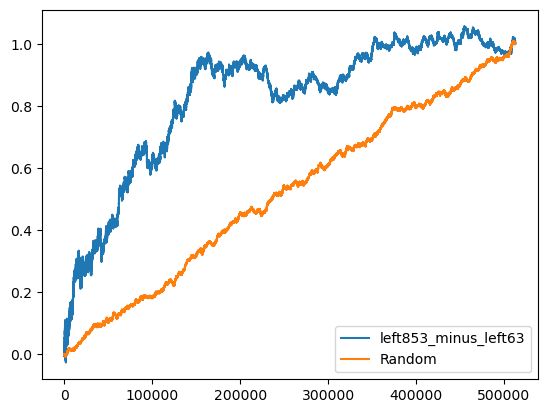

In [28]:
# 从 6张3元 升级到 8元+5张3：
vis.draw_auuc(
    BASE_FMT_v3,
    treatments=[2], #8元+5张3
    ite_names=['left853_minus_left63'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=1,
    show_curve=1
)

left65_minus_left63    0.823436
Random                 0.479775
dtype: float64
****************************************


[left65_minus_left63    0.823436
 Random                 0.479775
 dtype: float64]

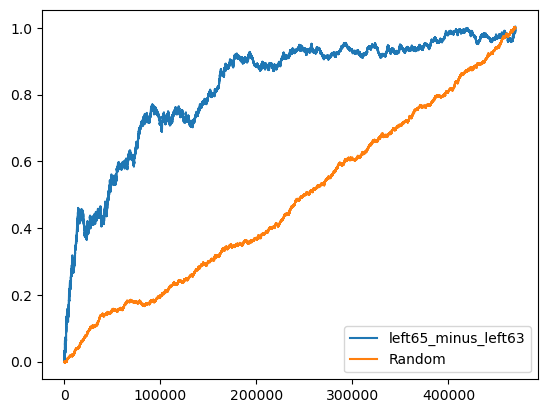

In [29]:
# 从 6张3元 升级到6张5元
vis.draw_auuc(
    BASE_FMT_v3,
    treatments=[3],
    ite_names=['left65_minus_left63'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=1,
    show_curve=1
)

left1053_minus_left63    0.795297
Random                   0.505995
dtype: float64
****************************************


[left1053_minus_left63    0.795297
 Random                   0.505995
 dtype: float64]

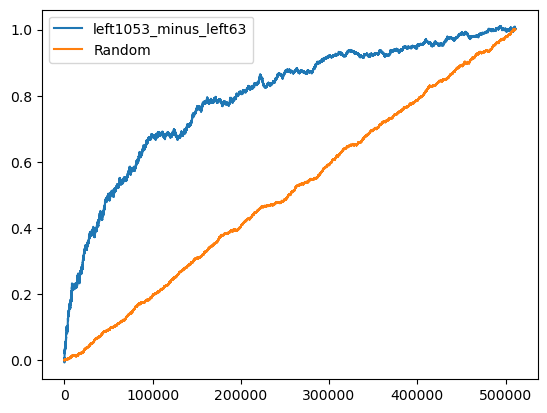

In [30]:
vis.draw_auuc(
    BASE_FMT_v3,
    treatments=[4],
    ite_names=['left1053_minus_left63'],
    label_col='label',
    curve_type='auuc',
    real_treatment='real_treatment',
    control_group_name=1,
    show_curve=1
)